In [1]:
import os

import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from skimage import filters

from scipy import stats

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
mesh_database_path = r"E:\2022_tanashi_broccoli\99_broccoli_models"

mesh_db = []
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db.append(os.path.join(mesh_database_path, file))

In [3]:
def mesh2pcd(mesh):
    mesh_pcd = o3d.geometry.PointCloud()
    mesh_pcd.points = mesh.vertices
    mesh_pcd.colors = mesh.vertex_colors
    mesh_pcd.normals = mesh.vertex_normals
    
    return mesh_pcd

def PCA(data, correlation=False, sort=True):
    """
    # 功能：计算PCA的函数
    # 输入：
    #     data：点云，NX3的矩阵
    #     correlation：区分np的cov和corrcoef，不输入时默认为False
    #     sort: 特征值排序，排序是为了其他功能方便使用，不输入时默认为True
    # 输出：
    #     eigenvalues：特征值
    #     eigenvectors：特征向量
    """
    # ==========start=============
    pcd_xyz = data
    pcd_mean = pcd_xyz.mean(axis=0)
    pcd_xyz_scaled = pcd_xyz - pcd_mean
    
    cov = np.cov(pcd_xyz_scaled.T)
    eigenvalues, eigenvectors = np.linalg.eig(cov)
    # ===========end==============
    if sort:
        sort = eigenvalues.argsort()[::-1]
        eigenvalues = eigenvalues[sort]
        eigenvectors = eigenvectors[:, sort]

    return eigenvalues, eigenvectors

In [4]:
# test mesh
mesh = o3d.io.read_triangle_mesh(mesh_db[10])

In [5]:
pcd = mesh2pcd(mesh)

In [6]:
_, v = PCA(np.asarray(pcd.points))
v[:, 2]

array([-0.96823764, -0.24884062, -0.02437672])

In [7]:
# data prepare
points = [np.asarray([0,0,0]), v[:,0]/10, v[:,1]/10, v[:,2]/10]
lines = [[0, 1], [0, 2], [0, 3]]  # points的id，而不是具体的值
colors = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]   # rgb来代表第一、第二、第三

# 设置lineset类
line_set = o3d.geometry.LineSet()
line_set.points = o3d.utility.Vector3dVector(points)
line_set.lines = o3d.utility.Vector2iVector(lines)
line_set.colors = o3d.utility.Vector3dVector(colors) 

# bbox
obb = pcd.get_oriented_bounding_box()
obb.color = (0, 0, 0)

In [41]:
# 可视化
o3d.visualization.draw_geometries([pcd, line_set, obb])

![](images/02_pca_obb.png)

可以看出来并不是跟obb完全的吻合，但是主成分(红线)基本上就是要的点了，然后还需要判断红线的方向，取点最多的方向为主轴(z轴的正方向)

然后换一个数据集就更清楚了，PCA不能代替BBox来找z方向

![](images/02_pca_on_no10.png)

In [9]:
v

array([[-0.23497948,  0.08544311, -0.96823764],
       [ 0.87229668, -0.4209238 , -0.24884062],
       [ 0.42881598,  0.90306292, -0.02437672]])

In [10]:
a = np.array([[1, 2, 3], [4, 5, 6]])   # vector u
b = np.array([5, 6, 2])   # vector v:
  
# finding norm of the vector v
b_norm = np.sqrt(sum(b**2))    
  
# Apply the formula as mentioned above
# for projecting a vector onto another vector
# find dot product using np.dot()
proj_of_a_on_b = (np.dot(a, b.reshape(3,1))/b_norm**2)*b
proj_of_a_on_b

# expected point1: [1.76923077 2.12307692 0.70769231]

array([[1.76923077, 2.12307692, 0.70769231],
       [4.76923077, 5.72307692, 1.90769231]])

In [11]:
def project_points_on_vector(points, vector):
    """
    把点投影到给定向量上
    输入：points: nx3的三维点
         vector: 1x3的向量
    输出：投影后的点(在空间中的位置)
    """
    v_norm = np.sqrt(sum(vector**2))
    
    return (np.dot(points, vector.reshape(3,1))/v_norm**2)*vector

In [12]:
project_points_on_vector(a, b)

array([[1.76923077, 2.12307692, 0.70769231],
       [4.76923077, 5.72307692, 1.90769231]])

In [13]:
# calculate the distance
np.sqrt(np.sum(proj_of_a_on_b**2, axis=1))

array([2.8527989 , 7.69015354])

In [14]:
pcd_on_pca1 = project_points_on_vector(np.asarray(pcd.points), v[:,0])

In [15]:
pcd_on_pca1

array([[-0.00546805,  0.02029863,  0.00997869],
       [-0.00567821,  0.02107879,  0.01036221],
       [-0.00579736,  0.02152109,  0.01057964],
       ...,
       [-0.00641314,  0.02380703,  0.0117034 ],
       [-0.00681244,  0.02528932,  0.01243208],
       [-0.00651725,  0.02419351,  0.01189339]])

In [16]:
temp_pcd = o3d.geometry.PointCloud()
temp_pcd.points = o3d.utility.Vector3dVector(pcd_on_pca1)
temp_pcd.colors = mesh.vertex_colors

In [17]:
o3d.visualization.draw_geometries([temp_pcd, line_set, obb])

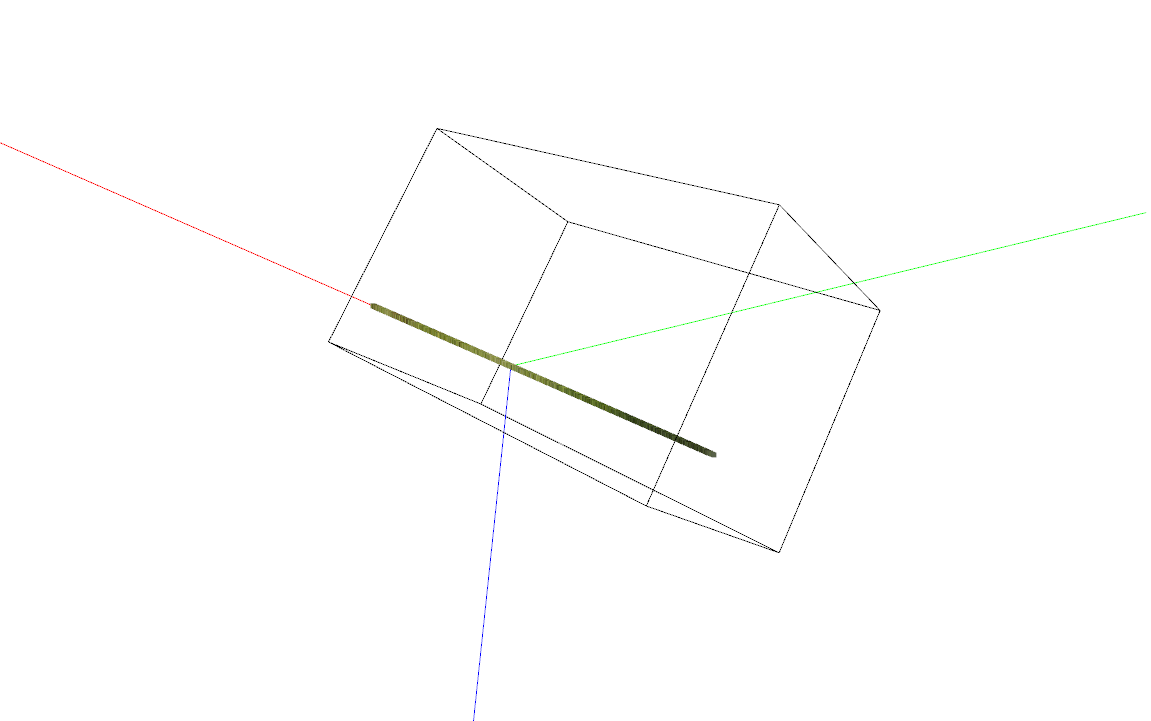

In [18]:
pcd_on_pca1.max(axis=0)

array([0.01534087, 0.0855023 , 0.04203244])

In [19]:
np.argmax(pcd_on_pca1, axis=0)

array([ 51091, 152299, 152299], dtype=int64)

In [20]:
np.argmin(pcd_on_pca1, axis=0)

array([152299,  51091,  51091], dtype=int64)

In [21]:
t_color = np.asarray(temp_pcd.colors)

t_color[32379,:] = [1, 0, 0]
t_color[23176,:] = [0, 0, 1]

temp_pcd.colors = o3d.utility.Vector3dVector(t_color)

In [22]:
o3d.visualization.draw_geometries([temp_pcd, line_set, obb])

![](images/02_pca1_max_min.png)

In [23]:
v[:,0]

array([-0.23497948,  0.87229668,  0.42881598])

In [24]:
pcd_on_pca1 / v[:,0]

array([[0.02327033, 0.02327033, 0.02327033],
       [0.0241647 , 0.0241647 , 0.0241647 ],
       [0.02467175, 0.02467175, 0.02467175],
       ...,
       [0.02729236, 0.02729236, 0.02729236],
       [0.02899165, 0.02899165, 0.02899165],
       [0.02773541, 0.02773541, 0.02773541]])

In [25]:
pcd_on_pca1_unit = (pcd_on_pca1 / v[:,0])[:,0]
pcd_on_pca1_unit

array([0.02327033, 0.0241647 , 0.02467175, ..., 0.02729236, 0.02899165,
       0.02773541])

In [26]:
np.argmax(pcd_on_pca1_unit)

152299

In [27]:
# calculate the direction

## calculate the middle point
pmax = pcd_on_pca1_unit.max()
pmin = pcd_on_pca1_unit.min()
pmid = (pmax + pmin) / 2
pmean = pcd_on_pca1_unit.mean()
pmedian = np.median(pcd_on_pca1_unit)

## calculate the kde peak
kde = stats.gaussian_kde(pcd_on_pca1_unit)
xx = np.linspace(pmin, pmax, 1000)
yy = kde(xx)

## calculate the otsu thresh
otsu = filters.threshold_otsu(pcd_on_pca1_unit)

max_peak = xx[np.argmax(yy)]

## calculate the local valley
peak = (np.diff(np.sign(np.diff(yy))) < 0).nonzero()[0] + 1 
valley = (np.diff(np.sign(np.diff(yy))) > 0).nonzero()[0] + 1 

In [28]:
pmean, pmid, max_peak

(0.04679200536435819, 0.016366866760378795, 0.04979632643651913)

In [29]:
valley, len(valley)

(array([113, 204, 254, 340, 818, 929], dtype=int64), 6)

In [30]:
if pmean < pmid:
    vz = v[:,0] * -1
else:
    vz = v[:,0]

In [31]:
vz

array([-0.23497948,  0.87229668,  0.42881598])

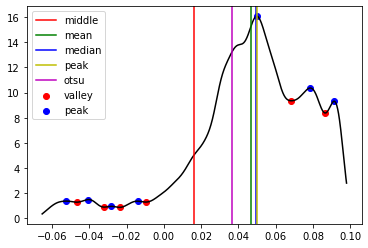

In [32]:
fig, ax = plt.subplots(1,1)
ax.plot(xx, yy, color='k')
ax.axvline(x=pmid, color='r', label="middle")
ax.axvline(x=pmean, color='g', label="mean")
ax.axvline(x=pmedian, color='b', label="median")
ax.axvline(x=max_peak, color='y', label="peak")
ax.axvline(x=otsu, color='m', label="otsu")
ax.scatter(xx[valley], yy[valley], color='r', label="valley")
ax.scatter(xx[peak], yy[peak], color='b', label="peak")

plt.legend()
plt.show()

In [33]:
# transform
cvtmat = np.vstack([v[:,1], v[:,2], vz]).T
cvtmat

array([[ 0.08544311, -0.96823764, -0.23497948],
       [-0.4209238 , -0.24884062,  0.87229668],
       [ 0.90306292, -0.02437672,  0.42881598]])

In [34]:
cvt_points = np.linalg.inv(cvtmat).dot(np.asarray(pcd.points).T).T

temp_pcd.points = o3d.utility.Vector3dVector(cvt_points)

In [35]:
axes_set = o3d.geometry.LineSet()
axes_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0],[0.1,0,0],[0,0.1,0], [0,0,0.1]]))
axes_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
axes_set.colors = o3d.utility.Vector3dVector(np.array([[1,0,0],[0,1,0],[0,0,1]]))

In [36]:
o3d.visualization.draw_geometries([temp_pcd, axes_set])

In [39]:
# filter colors
if pmean < pmid:
    rm_idx = np.where(pcd_on_pca1_unit > max_peak)
else:
    rm_idx = np.where(pcd_on_pca1_unit < max_peak)
    

t_color = np.asarray(temp_pcd.colors)

t_color[rm_idx, :] = [0.5, 0.5, 0.5]

temp_pcd.colors = o3d.utility.Vector3dVector(t_color)

In [42]:
o3d.visualization.draw_geometries([temp_pcd, axes_set])

![](images/02_pca1_kde_peak.png)

感觉还是得先摆正了然后在切

In [104]:
# find relationship between cvtmat and R
from copy import deepcopy

pcd_r = deepcopy(pcd)
pcd_r = pcd_r.rotate(cvtmat, center=[0,0,0])

In [106]:
o3d.visualization.draw_geometries([temp_pcd, pcd_r, axes_set])

![](images/02_cvtmat_direct.png)

In [109]:
rev_cvtmat = np.linalg.inv(cvtmat)

In [110]:
pcd_r = deepcopy(pcd)
pcd_r = pcd_r.rotate(rev_cvtmat, center=[0,0,0])

In [113]:
o3d.visualization.draw_geometries([pcd_r, temp_pcd, axes_set])

![](images/02_cvtmat_rev.png)

success!